# Practice lab: whom to call, and whom to nudge (solutions)

The TA-led practice lab after the second block, and extra practice afterwards. It runs about 75 minutes with a TA and longer alone. Fill each TODO, run the cell, and read the progress line under it: TODO until you fill it, then PASS or FAIL.

| Step | What you do | Minutes |
|---|---|---|
| 1 | Read the situation and the six seats | 5 |
| 2 | Build: split, baseline, model on the bank's calls | 15 |
| 3 | Assignment: a second baseline of your own, a simple rule | 15 |
| 4 | Integration with Week 2: Kalpa's repeat flag in SQL, with a cutoff date | 20 |
| 5 | QA: try to break your own result | 10 |
| 6 | The five-line write-up | 10 |

**Search terms:** baseline model, rule-based baseline, label leakage, SQL window by date, sanity check with shuffled labels.

## 1. The situation and the six seats

A Portuguese bank's campaign team (UCI Bank Marketing, 41,188 calls, CC BY 4.0) wants to rank clients so agents call the likeliest first. Kalpa Retail's Marketing wants the same shape of answer for its Rs 40 nudge: which members will buy again within ninety days. Kavya Nair, the senior analyst, wants the dumbest baseline before any model.

| Seat | The question this seat asks today |
|---|---|
| Business owner | Does the model change whom we call, and is that worth the build? |
| Product manager | What does the campaign team see, and when do they see it? |
| Solution architect | Where is the target computed, and as of which date? |
| Senior ML engineer (today's spotlight) | What is predicted, from what, known when; what is the bar; which rows score it? |
| Implementation engineer | Does the same split and the same score come out on every laptop? |
| QA and tester | What would break this number, and did we try it? |

In [1]:
# Tools for this notebook, and one helper that prints a check as PASS or FAIL.
import io, zipfile, pathlib, urllib.request
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

def check(label, ok):
    print(("PASS  " if ok else "FAIL  ") + label)

def todo_or(label, ok, value):
    """Print TODO while a step still holds None, then PASS or FAIL once it is filled."""
    if value is None:
        print("TODO  " + label)
    else:
        check(label, ok())

In [2]:
# Load the day's public dataset once; later runs read the cached copy.
CACHE = pathlib.Path.home() / ".cache" / "c2_datasets"
CACHE.mkdir(parents=True, exist_ok=True)

def load_bank():
    """UCI Bank Marketing, bank-additional-full.csv (CC BY 4.0), cached after the first download."""
    f = CACHE / "bank-additional-full.csv"
    if not f.exists():
        url = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"
        outer = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url, timeout=60).read()))
        inner = zipfile.ZipFile(io.BytesIO(outer.read("bank-additional.zip")))
        f.write_bytes(inner.read("bank-additional/bank-additional-full.csv"))
    return pd.read_csv(f, sep=";")

bank = load_bank()
print(bank.shape)
check("the bank file has 41,188 rows", len(bank) == 41188)

(41188, 21)
PASS  the bank file has 41,188 rows


## 2. Build: the split, the baseline, the model

The week's pipeline is loaded for you. Use seed 42 exactly as the class did, so your numbers match the room's.

In [3]:
# The week's pipeline: the same columns, the same split and the same model every day.
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# The customer table on the morning of the call: who the client is and how earlier campaigns went.
PROFILE = ["age", "job", "marital", "education", "default", "housing", "loan"]
HISTORY = ["contact", "month", "day_of_week", "campaign", "previous", "poutcome"]
COLUMNS = PROFILE + HISTORY

def week_split(df, seed=42):
    """Test is sealed first (20 percent, the envelope); the rest splits 75/25 into train and validation."""
    y = (df["y"] == "yes").astype(int)
    rest, test = train_test_split(df.index, test_size=0.20, stratify=y, random_state=seed)
    train, val = train_test_split(rest, test_size=0.25, stratify=y.loc[rest], random_state=seed)
    return df.loc[train], df.loc[val], df.loc[test]

def logistic(columns, df):
    # pandas 3 reads text as the "str" dtype, so test for numbers rather than for object.
    num = [c for c in columns if pd.api.types.is_numeric_dtype(df[c])]
    cat = [c for c in columns if c not in num]
    prep = ColumnTransformer([("num", StandardScaler(), num),
                              ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])
    return Pipeline([("prep", prep), ("model", LogisticRegression(max_iter=2000))])

# 2a: the week's split with seed 42.
train, val, test = week_split(bank, seed=42)
y_train = (train["y"] == "yes").astype(int)
y_val = (val["y"] == "yes").astype(int)

# 2b: the majority-class baseline on validation.
baseline = float((y_val == 0).mean())

# 2c: the logistic model on the 13 columns, scored at 0.5.
model = logistic(COLUMNS, bank).fit(train[COLUMNS], y_train)
model_acc = accuracy_score(y_val, model.predict(val[COLUMNS]))
print(f"baseline {baseline:.4f}, model {model_acc:.4f}")

todo_or("2a: validation has 8,238 rows", lambda: len(val) == 8238, val)
todo_or("2b: baseline 0.8874", lambda: round(baseline, 4) == 0.8874, baseline)
todo_or("2c: the model beats the baseline", lambda: model_acc > baseline, model_acc)

baseline 0.8874, model 0.8971
PASS  2a: validation has 8,238 rows
PASS  2b: baseline 0.8874
PASS  2c: the model beats the baseline


## 3. Assignment: a second baseline of your own

A baseline can be smarter than "say no to everyone". Write one rule a campaign manager could apply with no model at all, using one or two of the 13 columns, and score it on validation. Does it beat the majority class? Does it beat the model?

Pick your rule from what you know about the business before you look at any numbers, and write down why you expect it to work.

In [4]:
# 3: call only clients whose previous campaign ended in success.
# Why expect it: a client who said yes to the bank before is the warmest lead an agent has.
rule = val["poutcome"] == "success"
rule_acc = accuracy_score(y_val, rule.astype(int))
print(f"rule calls {int(rule.sum())} clients; accuracy {rule_acc:.4f} against baseline {baseline:.4f} and model {model_acc:.4f}")
todo_or("3: the rule is scored on all 8,238 validation rows", lambda: len(rule) == 8238, rule)
check("this rule beats the majority class", rule_acc > baseline)
check("this one-line rule scores at least as well as the model on accuracy", rule_acc >= model_acc)

rule calls 284 clients; accuracy 0.8988 against baseline 0.8874 and model 0.8971
PASS  3: the rule is scored on all 8,238 validation rows
PASS  this rule beats the majority class
PASS  this one-line rule scores at least as well as the model on accuracy


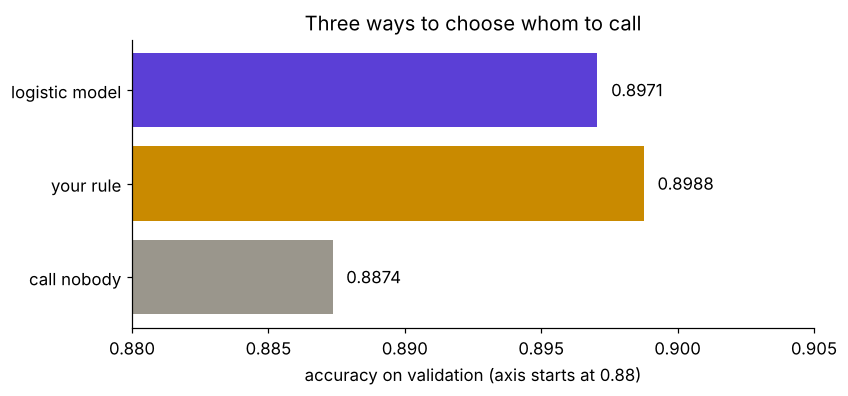

In [5]:
# Picture the three bars on validation: doing nothing, your rule, the model.
scores = {"call nobody": baseline, "your rule": rule_acc, "logistic model": model_acc}
shown = {k: v for k, v in scores.items() if v is not None}
if len(shown) < 3:
    print("Fill TODO 2 and 3 to draw the comparison; here is the bar every option must clear:", round(0.8874, 4))
    shown = {"call nobody (from class)": 0.8874}
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.barh(list(shown), list(shown.values()), color=["#9A968C", "#C98A00", "#5B3FD6"][:len(shown)])
for i, v in enumerate(shown.values()):
    ax.text(v + 0.0005, i, f"{v:.4f}", va="center")
ax.set_xlim(0.88, 0.905); ax.set_xlabel("accuracy on validation (axis starts at 0.88)")
ax.set_title("Three ways to choose whom to call")
plt.show()

## 4. Integration with Week 2: Kalpa's repeat flag in SQL, with a cutoff date

The Codespace's Postgres warehouse (loaded by `.devcontainer/load_warehouse.sh`) holds Kalpa Retail's `orders` table from Week 2: one row per order, with `customer_id`, `order_date`, `amount` and `status`. The helper below runs a query there; if no Postgres server answers, it loads the same warehouse file into an in-memory SQLite database and runs the same SQL, so the numbers are identical either way.

The prediction time is 30 June 2026. The target is: at least one delivered order in the ninety days after it, 1 July to 28 September.

In [6]:
# Run SQL against the Codespace warehouse, or against the same file in memory if no server answers.
import os, sqlite3, subprocess, shutil

WAREHOUSE = pathlib.Path("../../../W02/D1/data/C2_W02_D01_warehouse_v4_STUDENT.sql")

def from_postgres(sql):
    if not shutil.which("psql"):
        return None
    env = dict(os.environ, PGHOST=os.environ.get("PGHOST", "localhost"), PGUSER=os.environ.get("PGUSER", "postgres"),
               PGPASSWORD=os.environ.get("PGPASSWORD", "postgres"), PGDATABASE=os.environ.get("PGDATABASE", "kalpa"))
    r = subprocess.run(["psql", "-X", "--csv", "-c", sql], capture_output=True, text=True, env=env, timeout=60)
    return pd.read_csv(io.StringIO(r.stdout)) if r.returncode == 0 else None

def sqlite_copy():
    """The warehouse file's orders block, loaded into SQLite in memory; nothing is written to disk."""
    text = WAREHOUSE.read_text(encoding="utf-8")
    block = text.split("COPY orders")[1].split("\\.")[0].splitlines()[1:]
    rows = [line.split("\t") for line in block if line.strip()]
    db = sqlite3.connect(":memory:")
    pd.DataFrame(rows, columns=["order_id", "customer_id", "order_date", "quarter", "channel", "amount", "status"]) \
      .astype({"amount": float}).to_sql("orders", db, index=False)
    return db

def run_sql(sql):
    out = from_postgres(sql)
    if out is not None:
        print("ran on Postgres")
        return out
    print("no Postgres server answered, so the same SQL ran on SQLite in memory")
    return pd.read_sql_query(sql, sqlite_copy())

n = run_sql("select count(*) as orders, min(order_date) as first_day, max(order_date) as last_day from orders")
print(n.to_string(index=False))
check("the warehouse answered with 1,000 orders", int(n.loc[0, "orders"]) == 1000)

ran on Postgres
 orders  first_day   last_day
   1000 2026-04-01 2026-09-28
PASS  the warehouse answered with 1,000 orders


**The naive version, first.** A hurried analyst writes the flag on the whole table: a member "repeats" if they have more than one delivered order, and the feature is their order count. Run it and look at the two columns side by side.

In [7]:
# The naive flag: written on the whole log, with no cutoff date.
naive = run_sql("""
    select customer_id,
           count(*) as orders_ever,
           case when count(*) > 1 then 1 else 0 end as repeat_naive
    from orders
    where status = 'delivered'
    group by customer_id
""")
rule_says = (naive["orders_ever"] >= 2).astype(int)
print(f"{len(naive)} members; a 'model' that reads orders_ever is right {(rule_says == naive['repeat_naive']).mean():.0%} of the time")
check("the naive feature predicts the naive flag perfectly", (rule_says == naive["repeat_naive"]).all())

ran on Postgres
268 members; a 'model' that reads orders_ever is right 100% of the time
PASS  the naive feature predicts the naive flag perfectly


**The leak, named.** The naive flag and its feature count the same orders, including orders placed after any date Marketing could nudge on, so the feature contains the answer and any model reading it scores 100 percent. It is the chapter 2 trap at warehouse scale. Now write the honest version: inputs from orders on or before 30 June, the target from the window after it.

In [8]:
# 4: the honest query, with the cutoff and the window written as literal dates.
HONEST_SQL = """
    with hist as (
        select customer_id, count(*) as orders_before, max(order_date) as last_before
        from orders
        where status = 'delivered' and order_date <= '2026-06-30'
        group by customer_id),
    win as (
        select distinct customer_id
        from orders
        where status = 'delivered' and order_date > '2026-06-30' and order_date <= '2026-09-28')
    select h.customer_id, h.orders_before, h.last_before,
           case when w.customer_id is null then 0 else 1 end as repeat_90d
    from hist h left join win w on w.customer_id = h.customer_id
    order by h.customer_id
"""
honest = run_sql(HONEST_SQL)
honest["days_since_last"] = (pd.Timestamp("2026-06-30") - pd.to_datetime(honest["last_before"])).dt.days
print(honest.head().to_string(index=False))
print(f"{len(honest)} members with history; {int(honest['repeat_90d'].sum())} bought again in the window, share {honest['repeat_90d'].mean():.3f}")
todo_or("4: one row per member with history, and the window flag", lambda: len(honest) == 205 and int(honest["repeat_90d"].sum()) == 110, honest)

ran on Postgres
customer_id  orders_before last_before  repeat_90d  days_since_last
     C-0001              1  2026-04-05           0               86
     C-0002              1  2026-04-20           1               71
     C-0003              2  2026-06-05           1               25
     C-0007              1  2026-05-03           1               58
     C-0008              1  2026-05-06           0               55
205 members with history; 110 bought again in the window, share 0.537
PASS  4: one row per member with history, and the window flag


In [9]:
# 4b: here the majority class is "buys again", so the dumbest model nudges everyone.
share = honest["repeat_90d"].mean()
kalpa_baseline = max(share, 1 - share)
print(f"majority class: {'buys again' if share > 0.5 else 'does not'}; baseline accuracy {kalpa_baseline:.3f}")
rule_kalpa = (honest["orders_before"] >= 2).astype(int)
print(f"a rule, 'nudge members with two or more orders before the cutoff': accuracy {(rule_kalpa == honest['repeat_90d']).mean():.3f}")
todo_or("4b: the majority-class baseline on Kalpa's flag", lambda: round(kalpa_baseline, 3) == 0.537, kalpa_baseline)

majority class: buys again; baseline accuracy 0.537
a rule, 'nudge members with two or more orders before the cutoff': accuracy 0.566
PASS  4b: the majority-class baseline on Kalpa's flag


## 5. QA: try to break your own result

Two attacks a tester would run. First, shuffle the target in the training rows: a model that learns from noise should fall back to the baseline, and if it does not, something leaks. Second, change the seed: the edge over the baseline should stay roughly where it was, and how far it moves tells you how much of the edge is luck.

In [10]:
# 5a: shuffled labels, so the columns carry no signal about the target.
y_shuffled = pd.Series(np.random.default_rng(0).permutation(y_train.values), index=y_train.index)
shuffled_acc = accuracy_score(y_val, logistic(COLUMNS, bank).fit(train[COLUMNS], y_shuffled).predict(val[COLUMNS]))
# 5b: the same build on a different seed.
tr7, va7, _ = week_split(bank, seed=7)
y_tr7, y_va7 = (tr7["y"] == "yes").astype(int), (va7["y"] == "yes").astype(int)
acc7 = accuracy_score(y_va7, logistic(COLUMNS, bank).fit(tr7[COLUMNS], y_tr7).predict(va7[COLUMNS]))
seed7_edge = acc7 - (y_va7 == 0).mean()
print(f"shuffled labels: {shuffled_acc:.4f} against baseline {baseline:.4f}")
print(f"seed 7: model {acc7:.4f}, baseline {(y_va7 == 0).mean():.4f}, edge {100 * seed7_edge:.2f} points (seed 42: {100 * (model_acc - baseline):.2f})")
todo_or("5a: the shuffled-label model scores no better than the baseline plus 0.002", lambda: shuffled_acc <= baseline + 0.002, shuffled_acc)
todo_or("5b: the seed-7 edge is still positive", lambda: seed7_edge > 0, seed7_edge)

shuffled labels: 0.8874 against baseline 0.8874
seed 7: model 0.8977, baseline 0.8874, edge 1.03 points (seed 42: 0.97)
PASS  5a: the shuffled-label model scores no better than the baseline plus 0.002
PASS  5b: the seed-7 edge is still positive


## 6. The five-line write-up (a model answer)

1. **Claim:** on the bank's validation slice the logistic model beats calling nobody by about one point of accuracy (0.8971 against 0.8874), and a one-line rule, call clients whose last campaign succeeded, does as well (0.8988).
2. **Evidence:** the same seed-42 split as the class; the shuffled-label model falls to the baseline, so nothing leaks; seed 7 keeps a positive edge of similar size.
3. **Caveat:** accuracy on a 89 to 11 split rewards saying no; the random split mixes 2008 with 2010; and Kalpa's own flag (110 of 205 members, 0.537) has the opposite majority.
4. **Action:** ship the rule as the Friday baseline for the campaign team and keep the model in validation until it beats the rule on the measure Tuesday chooses.
5. **Next check:** Tuesday's count of how many of the 928 yes clients each option actually puts on the call list.